# Aggregate vs Baseline — Comparison + Statistical Significance

Walks the `outputs/` tree (same layout `scripts/aggregate_eval_slurm.sh` writes into), collects every `(model, seed)` result for the two evaluation paradigms, merges with the best baseline per source, visualizes the comparison, and runs paired significance tests with Benjamini-Hochberg FDR correction.

**Two data forks discovered per checkpoint:**
- `<run>/<ts>/aggregate_test_eval/metrics_aggregate_<split>.json` — 6-class multiclass on aggregate's own test split.
- `<run>/<ts>/aggregate_eval/aggregate_eval_<split>.json` — per-source binary on each of the 7 source datasets' own test splits.

**Statistical question:** for each `(aggregate_model, source)` pair, is the aggregate's per-source binary F1 significantly higher than the best baseline's binary F1 across seeds? Since ML variance across seeds isn't necessarily Gaussian, we default to the non-parametric **Wilcoxon signed-rank** test and also report the paired t-test + effect size for cross-reference. BH-FDR corrects for the multiple sources / models being tested.

In [17]:
from __future__ import annotations

import json
import statistics
from collections import defaultdict
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")

# ── Paths — edit for your local layout ─────────────────────────────────────
OUTPUTS_DIR = Path("/Users/basel.alshaikhdeeb/Documents/output_aggregate/outputs").resolve()
BASELINES_DIR = Path("/Users/basel.alshaikhdeeb/Documents/outputs_binary").resolve()  # usually same tree; can point elsewhere
BEST_MODELS_YAML = Path("/Users/basel.alshaikhdeeb/Documents/medrel-inference/best_models_binary.yaml").resolve()  # optional; falls back to auto-selection
SPLIT = "test"
DATASET_TAG = "aggregate"  # switch to "aggregate_binary" for the new binary corpus

print(f"outputs_dir:       {OUTPUTS_DIR}  exists={OUTPUTS_DIR.exists()}")
print(f"baselines_dir:     {BASELINES_DIR}  exists={BASELINES_DIR.exists()}")
print(f"best_models_yaml:  {BEST_MODELS_YAML}  exists={BEST_MODELS_YAML.exists()}")
print(f"split:             {SPLIT}")
print(f"dataset_tag:       {DATASET_TAG}")

outputs_dir:       /Users/basel.alshaikhdeeb/Documents/output_aggregate/outputs  exists=True
baselines_dir:     /Users/basel.alshaikhdeeb/Documents/outputs_binary  exists=True
best_models_yaml:  /Users/basel.alshaikhdeeb/Documents/medrel-inference/best_models_binary.yaml  exists=True
split:             test


## 1. Discovery

One pass over the tree produces three DataFrames:

* `df_agg` — one row per `(model, seed)`; 6-class aggregate/test metrics.
* `df_bin` — one row per `(model, source, seed)`; per-source binary metrics.
* `df_baseline` — one row per `(model, dataset, seed)`; multiclass or binary baseline metrics (mode auto-detected).

In [18]:
def _read_config_snapshot(ts_dir: Path) -> dict:
    p = ts_dir / "config_snapshot.yaml"
    if not p.exists():
        return {}
    try:
        return yaml.safe_load(p.read_text()) or {}
    except Exception:
        return {}


def collect_all(outputs_dir: Path, baselines_dir: Path, split: str, dataset_tag: str = "aggregate"):
    agg_rows, bin_rows, baseline_rows = [], [], []

    # Aggregate-trained models -----------------------------------------------
    for run_dir in sorted(outputs_dir.iterdir()):
        if not run_dir.is_dir():
            continue
        parts = run_dir.name.split("__")
        if len(parts) < 3 or parts[1] != dataset_tag:
            continue
        model = parts[0]
        # tolerate 'seed42' or 'seed42__binary' suffixes
        seed = parts[2].replace("seed", "").split("__")[0]

        for ts_dir in sorted(run_dir.iterdir()):
            if not ts_dir.is_dir() or ts_dir.name.startswith("_"):
                continue

            agg_json = ts_dir / "aggregate_test_eval" / f"metrics_{dataset_tag}_{split}.json"
            if agg_json.exists():
                try:
                    payload = json.loads(agg_json.read_text())
                    e = payload.get("eval") if isinstance(payload, dict) and "eval" in payload else payload
                    agg_rows.append({
                        "model": model, "seed": seed,
                        "micro_f1": e.get("eval_micro_f1", e.get("micro_f1")),
                        "macro_f1": e.get("eval_macro_f1", e.get("macro_f1")),
                        "weighted_f1": e.get("eval_weighted_f1", e.get("weighted_f1")),
                        "accuracy": e.get("eval_accuracy", e.get("accuracy")),
                        "roc_auc_macro": e.get("eval_roc_auc_macro", e.get("roc_auc_macro")),
                        "roc_auc_weighted": e.get("eval_roc_auc_weighted", e.get("roc_auc_weighted")),
                    })
                except Exception as exc:
                    print(f"  warn: {agg_json}: {exc}")

            src_json = ts_dir / "aggregate_eval" / f"aggregate_eval_{split}.json"
            if src_json.exists():
                try:
                    payload = json.loads(src_json.read_text())
                    for src, m in (payload.get("per_source") or {}).items():
                        bin_rows.append({
                            "model": model, "seed": seed, "source": src,
                            "micro_f1": m.get("micro_f1"),
                            "macro_f1": m.get("macro_f1"),
                            "precision_positive": m.get("precision_positive"),
                            "recall_positive": m.get("recall_positive"),
                            "f1_positive": m.get("f1_positive"),
                            "n": m.get("n"),
                        })
                except Exception as exc:
                    print(f"  warn: {src_json}: {exc}")

    # Per-dataset baselines --------------------------------------------------
    for run_dir in sorted(baselines_dir.iterdir()):
        if not run_dir.is_dir():
            continue
        parts = run_dir.name.split("__")
        if len(parts) < 3:
            continue
        model, dataset = parts[0], parts[1]
        if dataset == dataset_tag:
            continue
        seed = parts[2].replace("seed", "").split("__")[0]

        for ts_dir in sorted(run_dir.iterdir()):
            if not ts_dir.is_dir() or ts_dir.name.startswith("_"):
                continue
            m_file = ts_dir / "metrics.json"
            if not m_file.exists():
                continue
            try:
                cfg = _read_config_snapshot(ts_dir)
                binary_mode = bool(cfg.get("dataset", {}).get("binary_mode", False))
                m = json.loads(m_file.read_text()).get("eval", {})
                baseline_rows.append({
                    "model": model, "dataset": dataset, "seed": seed,
                    "mode": "binary" if binary_mode else "multi",
                    "micro_f1": m.get("eval_micro_f1"),
                    "macro_f1": m.get("eval_macro_f1"),
                    "micro_precision": m.get("eval_micro_precision"),
                    "micro_recall": m.get("eval_micro_recall"),
                    "roc_auc": m.get("eval_roc_auc"),
                    "roc_auc_macro": m.get("eval_roc_auc_macro"),
                })
            except Exception as exc:
                print(f"  warn: {m_file}: {exc}")

    return pd.DataFrame(agg_rows), pd.DataFrame(bin_rows), pd.DataFrame(baseline_rows)


df_agg, df_bin, df_baseline = collect_all(OUTPUTS_DIR, BASELINES_DIR, SPLIT, DATASET_TAG)
print()
print(f"df_agg      : {len(df_agg):>5} rows | "
      f"models={df_agg['model'].nunique() if len(df_agg) else 0}, "
      f"seeds={df_agg['seed'].nunique() if len(df_agg) else 0}")
print(f"df_bin      : {len(df_bin):>5} rows | "
      f"models={df_bin['model'].nunique() if len(df_bin) else 0}, "
      f"sources={df_bin['source'].nunique() if len(df_bin) else 0}, "
      f"seeds={df_bin['seed'].nunique() if len(df_bin) else 0}")
print(f"df_baseline : {len(df_baseline):>5} rows | "
      f"models={df_baseline['model'].nunique() if len(df_baseline) else 0}, "
      f"datasets={df_baseline['dataset'].nunique() if len(df_baseline) else 0}, "
      f"seeds={df_baseline['seed'].nunique() if len(df_baseline) else 0}")
if len(df_baseline):
    print(f"              modes present: {dict(df_baseline['mode'].value_counts())}")


df_agg      :    79 rows | models=16, seeds=5
df_bin      :   552 rows | models=16, sources=7, seeds=5
df_baseline :   116 rows | models=3, datasets=8, seeds=5
              modes present: {'multi': 116}


In [19]:
# Load best_models.yaml if present; otherwise infer best baseline per source by mean micro_f1
pinned_baseline: dict[str, str] = {}
if BEST_MODELS_YAML.exists():
    pinned_baseline = yaml.safe_load(BEST_MODELS_YAML.read_text()) or {}
    print(f"Pinned best baselines from {BEST_MODELS_YAML}:")
    for k, v in pinned_baseline.items():
        print(f"  {k:<20} -> {v}")
else:
    print("No best_models.yaml — will auto-select the highest-mean-micro_f1 baseline per source.")


def resolve_baseline_model(source: str) -> str | None:
    if source in pinned_baseline and pinned_baseline[source] in df_baseline["model"].unique():
        return pinned_baseline[source]
    sub = df_baseline[df_baseline["dataset"] == source]
    if sub.empty:
        return None
    means = sub.groupby("model")["micro_f1"].mean()
    return means.idxmax() if not means.empty else None

Pinned best baselines from /Users/basel.alshaikhdeeb/Documents/medrel-inference/best_models_binary.yaml:
  bc5cdr               -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/biolinkbert-large__bc5cdr__seed7919__binary/2026-06-18_15-44-34/checkpoints/best
  biored               -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/pubmedbert-large__biored__seed2024__binary/2026-06-22_21-26-15/checkpoints/best
  chemprot             -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/pubmedbert-large__chemprot__seed7919__binary/2026-06-23_09-51-19/checkpoints/best
  drugprot             -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/gatortron__drugprot__seed456__binary/2026-06-22_03-14-05/checkpoints/best
  ddi                  -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/biolinkbert-large__ddi__seed456__binary/2026-06-18_23-45-30/checkpoints/best
  euadr                -> /Users/basel.alshaikhdeeb/Documents/outputs_binary/biolinkbert-large__euadr__seed42__binar

## 2. Aggregate/test — 6-class multiclass overview

How does the aggregate-trained model do on the aggregate corpus's own test split? Each row is one aggregate-trained model with mean ± std across seeds.

,n_seeds,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std,roc_auc_macro_mean
model,,,,,,
biolinkbert-base,5,0.8823,0.0011,0.8046,0.0037,0.9448
biolinkbert-large,5,0.8818,0.0013,0.7974,0.0076,0.9429
pubmedbert-large,5,0.8802,0.0026,0.7926,0.0033,0.9626
gatortron,4,0.8795,0.0020,0.7979,0.0074,0.9623
pubmedbert,5,0.8793,0.0012,0.7917,0.0056,0.9468
biogpt,5,0.8773,0.0010,0.7811,0.0046,0.9525
gpt2,5,0.8771,0.0009,0.7910,0.0028,0.9066
roberta-large,5,0.8759,0.0030,0.7845,0.0050,0.9269
biobert,5,0.8756,0.0023,0.7872,0.0043,0.9428


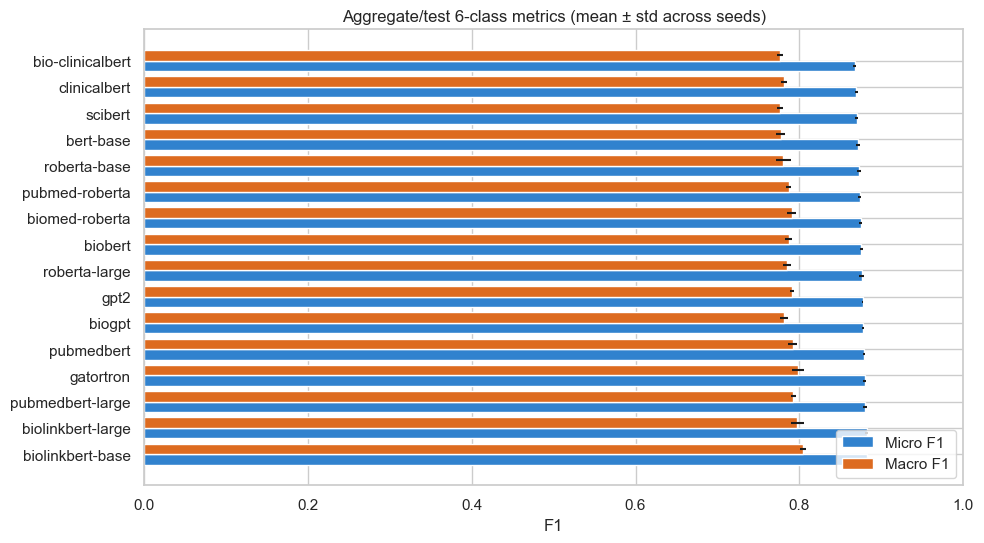

In [20]:
if len(df_agg):
    agg_summary = (
        df_agg.groupby("model")
        .agg(
            n_seeds=("seed", "nunique"),
            micro_f1_mean=("micro_f1", "mean"),
            micro_f1_std=("micro_f1", "std"),
            macro_f1_mean=("macro_f1", "mean"),
            macro_f1_std=("macro_f1", "std"),
            roc_auc_macro_mean=("roc_auc_macro", "mean"),
        )
        .sort_values("micro_f1_mean", ascending=False)
    )
    display(agg_summary.round(4))

    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(agg_summary))))
    y = np.arange(len(agg_summary))
    ax.barh(y - 0.2, agg_summary["micro_f1_mean"], height=0.4,
            xerr=agg_summary["micro_f1_std"].fillna(0), label="Micro F1", color="#3182ce")
    ax.barh(y + 0.2, agg_summary["macro_f1_mean"], height=0.4,
            xerr=agg_summary["macro_f1_std"].fillna(0), label="Macro F1", color="#dd6b20")
    ax.set_yticks(y)
    ax.set_yticklabels(agg_summary.index)
    ax.set_xlim(0, 1)
    ax.set_xlabel("F1")
    ax.set_title(f"Aggregate/{SPLIT} 6-class metrics (mean ± std across seeds)")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("No aggregate/test JSONs discovered.")

## 3. Per-source binary vs best baseline

For each source dataset, pair every `(aggregate_model, seed)` binary F1 with the best baseline model's F1 (matched by seed when possible). The result is one row per `(aggregate_model, source)` combo.

In [21]:
def _mean_std(values):
    vals = [v for v in values if v is not None and not (isinstance(v, float) and np.isnan(v))]
    if not vals:
        return (np.nan, 0.0)
    return float(np.mean(vals)), float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0


def _fmt_ms(mean, std, prec=4):
    if mean != mean:
        return "—"
    return f"{mean:.{prec}f} ± {std:.{prec}f}"


comparison_rows = []
for model in sorted(df_bin["model"].unique()):
    for source in sorted(df_bin["source"].unique()):
        agg_sub = df_bin[(df_bin["model"] == model) & (df_bin["source"] == source)]
        agg_vals = agg_sub["f1_positive"].tolist()
        agg_mean, agg_std = _mean_std(agg_vals)

        baseline_model = resolve_baseline_model(source)
        if baseline_model:
            bl_sub = df_baseline[(df_baseline["model"] == baseline_model) & (df_baseline["dataset"] == source)]
            bl_vals = bl_sub["micro_f1"].tolist()
            bl_mode = bl_sub["mode"].mode().iloc[0] if not bl_sub.empty else "—"
        else:
            bl_sub = pd.DataFrame()
            bl_vals = []
            bl_mode = "—"
        bl_mean, bl_std = _mean_std(bl_vals)

        delta = agg_mean - bl_mean if bl_mean == bl_mean else np.nan
        comparison_rows.append({
            "model": model, "source": source,
            "agg_n": len(agg_vals), "agg_f1(+)": _fmt_ms(agg_mean, agg_std),
            "baseline_model": baseline_model or "—",
            "bl_mode": bl_mode, "bl_n": len(bl_vals),
            "bl_micro_f1": _fmt_ms(bl_mean, bl_std),
            "delta": f"{delta:+.4f}" if delta == delta else "—",
            "_agg_mean": agg_mean, "_agg_std": agg_std,
            "_bl_mean": bl_mean, "_bl_std": bl_std, "_delta": delta,
            "_agg_vals": agg_vals, "_bl_vals": bl_vals,
            "_agg_seeds": agg_sub["seed"].tolist(),
            "_bl_seeds": bl_sub["seed"].tolist() if not bl_sub.empty else [],
        })

df_compare = pd.DataFrame(comparison_rows)
display_cols = ["model", "source", "agg_n", "agg_f1(+)", "baseline_model", "bl_mode", "bl_n", "bl_micro_f1", "delta"]
display(df_compare[display_cols])

,model,source,agg_n,agg_f1(+),baseline_model,bl_mode,bl_n,bl_micro_f1,delta
0,bert-base,bc5cdr,5,0.3824 ± 0.0168,biolinkbert-large,multi,5,0.9561 ± 0.0017,-0.5737
1,bert-base,biored,5,0.4917 ± 0.0163,pubmedbert-large,multi,5,0.7941 ± 0.0116,-0.3025
2,bert-base,chem_dis_gene,5,0.4690 ± 0.0087,pubmedbert-large,multi,5,0.9827 ± 0.0009,-0.5137
3,bert-base,chemprot,5,0.7221 ± 0.0054,biolinkbert-large,multi,5,0.9715 ± 0.0005,-0.2494
4,bert-base,ddi,5,0.7584 ± 0.0076,biolinkbert-large,multi,5,0.9855 ± 0.0006,-0.2271
...,...,...,...,...,...,...,...,...,...
107,scibert,chem_dis_gene,5,0.4780 ± 0.0101,pubmedbert-large,multi,5,0.9827 ± 0.0009,-0.5046
108,scibert,chemprot,5,0.7395 ± 0.0029,biolinkbert-large,multi,5,0.9715 ± 0.0005,-0.2321
109,scibert,ddi,5,0.7905 ± 0.0123,biolinkbert-large,multi,5,0.9855 ± 0.0006,-0.1950
110,scibert,drugprot,5,0.0000 ± 0.0000,gatortron,multi,2,0.9594 ± 0.0010,-0.9594


## 4. Statistical significance testing

For each `(aggregate_model, source)` row above, ask: **is the aggregate's binary F1 significantly higher than the baseline's?**

- **Pairing:** we match aggregate and baseline runs by seed when their seed sets overlap. If they don't (or if seed counts differ), we fall back to an unpaired test.
- **Primary test:** Wilcoxon signed-rank (non-parametric, one-sided: `aggregate > baseline`). With only 5 seeds Wilcoxon's minimum achievable p-value is ~0.031, so highly-significant results are rare — that's a sample-size limitation, not evidence against improvement.
- **Also reported:** paired t-test (parametric, higher power at small n; assumes Gaussian differences) and Cohen's d effect size.
- **Multiple-comparison correction:** Benjamini-Hochberg FDR across all rows.
- **Caveat about mode:** rows where the baseline was trained in **multi**-class mode aren't strictly comparable to the aggregate's binary F1 (they measure different things). Filter to `bl_mode == 'binary'` if you want a clean statistical claim; otherwise these rows are directional-only.

In [24]:
def cohens_d_paired(a, b):
    diffs = np.array(a) - np.array(b)
    if len(diffs) < 2 or np.std(diffs, ddof=1) == 0:
        return np.nan
    return float(np.mean(diffs) / np.std(diffs, ddof=1))


def cohens_d_indep(a, b):
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = np.sqrt(((len(a) - 1) * np.var(a, ddof=1) + (len(b) - 1) * np.var(b, ddof=1)) / (len(a) + len(b) - 2))
    if pooled == 0:
        return np.nan
    return float((np.mean(a) - np.mean(b)) / pooled)


def _bh_adjust(pvals: list[float]) -> list[float]:
    """Benjamini-Hochberg FDR-adjusted p-values."""
    m = len(pvals)
    if m == 0:
        return []
    order = np.argsort(pvals)
    ranked = np.array(pvals)[order]
    adj = ranked * m / (np.arange(m) + 1)
    # monotone from the largest rank downwards
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    adj = np.clip(adj, 0, 1)
    out = np.empty(m)
    out[order] = adj
    return out.tolist()


def significance_row(row):
    agg_vals = row["_agg_vals"]
    bl_vals = row["_bl_vals"]
    agg_seeds = row["_agg_seeds"]
    bl_seeds = row["_bl_seeds"]
    if len(agg_vals) < 2 or len(bl_vals) < 2:
        return {"pairing": "insufficient", "n_pairs": min(len(agg_vals), len(bl_vals)),
                "wilcoxon_p": np.nan, "ttest_p": np.nan, "cohens_d": np.nan}

    # Try to pair by seed. If seed sets don't align, fall back to unpaired MWU.
    shared = sorted(set(agg_seeds) & set(bl_seeds), key=lambda s: (int(s) if s.isdigit() else s))
    if len(shared) >= 2:
        a_map = {s: v for s, v in zip(agg_seeds, agg_vals)}
        b_map = {s: v for s, v in zip(bl_seeds, bl_vals)}
        a = [a_map[s] for s in shared]
        b = [b_map[s] for s in shared]
        diffs = np.array(a) - np.array(b)
        if np.all(diffs == 0):
            return {"pairing": "paired", "n_pairs": len(shared), "wilcoxon_p": 1.0, "ttest_p": 1.0, "cohens_d": 0.0}
        # Wilcoxon signed-rank (one-sided: aggregate > baseline)
        try:
            w = stats.wilcoxon(a, b, alternative="greater", zero_method="wilcox")
            wp = float(w.pvalue)
        except ValueError:
            wp = np.nan
        # Paired t-test
        try:
            t = stats.ttest_rel(a, b, alternative="greater")
            tp = float(t.pvalue)
        except Exception:
            tp = np.nan
        d = cohens_d_paired(a, b)
        return {"pairing": "paired", "n_pairs": len(shared),
                "wilcoxon_p": wp, "ttest_p": tp, "cohens_d": d}
    else:
        # Fall back to unpaired MWU + independent t-test
        u = stats.mannwhitneyu(agg_vals, bl_vals, alternative="greater")
        try:
            t = stats.ttest_ind(agg_vals, bl_vals, alternative="greater", equal_var=False)
            tp = float(t.pvalue)
        except Exception:
            tp = np.nan
        d = cohens_d_indep(agg_vals, bl_vals)
        return {"pairing": "unpaired", "n_pairs": f"{len(agg_vals)}v{len(bl_vals)}",
                "wilcoxon_p": float(u.pvalue), "ttest_p": tp, "cohens_d": d}


sig_records = df_compare.apply(significance_row, axis=1)
df_sig = pd.concat([df_compare, pd.DataFrame(list(sig_records))], axis=1)

# BH-FDR adjust across all tests
df_sig["wilcoxon_p_bh"] = _bh_adjust(df_sig["wilcoxon_p"].fillna(1.0).tolist())
df_sig["ttest_p_bh"] = _bh_adjust(df_sig["ttest_p"].fillna(1.0).tolist())
df_sig["significant_bh"] = df_sig["wilcoxon_p_bh"] < 0.05

sig_cols = ["model", "source", "agg_f1(+)", "baseline_model", "bl_mode", "bl_micro_f1",
            "delta", "pairing", "n_pairs", "wilcoxon_p", "wilcoxon_p_bh",
            "ttest_p", "cohens_d", "significant_bh"]
df_sig_display = df_sig[sig_cols].copy()
for col in ["wilcoxon_p", "wilcoxon_p_bh", "ttest_p", "cohens_d"]:
    df_sig_display[col] = df_sig_display[col].apply(
        lambda x: f"{x:.3g}" if isinstance(x, (int, float)) and x == x else "—"
    )
display(df_sig_display)

n_tested = int((df_sig["wilcoxon_p"].notna()).sum())
n_sig = int(df_sig["significant_bh"].sum())
print(f"\n{n_sig}/{n_tested} (model, source) comparisons show statistically significant improvement (Wilcoxon one-sided, BH-adjusted p < 0.05).")

,model,source,agg_f1(+),baseline_model,bl_mode,bl_micro_f1,delta,pairing,n_pairs,wilcoxon_p,wilcoxon_p_bh,ttest_p,cohens_d,significant_bh
0,bert-base,bc5cdr,0.3824 ± 0.0168,biolinkbert-large,multi,0.9561 ± 0.0017,-0.5737,paired,5,1,1,1,-36.7,False
1,bert-base,biored,0.4917 ± 0.0163,pubmedbert-large,multi,0.7941 ± 0.0116,-0.3025,paired,5,1,1,1,-11.5,False
2,bert-base,chem_dis_gene,0.4690 ± 0.0087,pubmedbert-large,multi,0.9827 ± 0.0009,-0.5137,paired,5,1,1,1,-63.6,False
3,bert-base,chemprot,0.7221 ± 0.0054,biolinkbert-large,multi,0.9715 ± 0.0005,-0.2494,paired,5,1,1,1,-43.3,False
4,bert-base,ddi,0.7584 ± 0.0076,biolinkbert-large,multi,0.9855 ± 0.0006,-0.2271,paired,5,1,1,1,-29.2,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,scibert,chem_dis_gene,0.4780 ± 0.0101,pubmedbert-large,multi,0.9827 ± 0.0009,-0.5046,paired,5,1,1,1,-52.5,False
108,scibert,chemprot,0.7395 ± 0.0029,biolinkbert-large,multi,0.9715 ± 0.0005,-0.2321,paired,5,1,1,1,-74.6,False
109,scibert,ddi,0.7905 ± 0.0123,biolinkbert-large,multi,0.9855 ± 0.0006,-0.1950,paired,5,1,1,1,-15.9,False
110,scibert,drugprot,0.0000 ± 0.0000,gatortron,multi,0.9594 ± 0.0010,-0.9594,paired,2,1,1,1,-956,False



0/112 (model, source) comparisons show statistically significant improvement (Wilcoxon one-sided, BH-adjusted p < 0.05).


In [25]:
# Same table, but restricted to baselines that were trained in binary mode
# (only these are directly comparable to aggregate's binary F1).
if (df_sig["bl_mode"] == "binary").any():
    df_sig_binary = df_sig[df_sig["bl_mode"] == "binary"].copy()
    df_sig_binary["wilcoxon_p_bh_strict"] = _bh_adjust(df_sig_binary["wilcoxon_p"].fillna(1.0).tolist())
    df_sig_binary["significant_strict"] = df_sig_binary["wilcoxon_p_bh_strict"] < 0.05
    print(f"Restricted to bl_mode='binary' — {(df_sig_binary['significant_strict']).sum()}/{len(df_sig_binary)} significant after re-doing BH on this subset.")
    show = ["model", "source", "agg_f1(+)", "baseline_model", "bl_micro_f1", "delta",
            "n_pairs", "wilcoxon_p", "wilcoxon_p_bh_strict", "cohens_d", "significant_strict"]
    for col in ["wilcoxon_p", "wilcoxon_p_bh_strict", "cohens_d"]:
        df_sig_binary[col] = df_sig_binary[col].apply(
            lambda x: f"{x:.3g}" if isinstance(x, (int, float)) and x == x else "—"
        )
    display(df_sig_binary[show])
else:
    print("No baselines with mode='binary' — statistical test above is directional-only (aggregate binary vs baseline multiclass isn't strictly comparable).")

No baselines with mode='binary' — statistical test above is directional-only (aggregate binary vs baseline multiclass isn't strictly comparable).


## 5. Visualizations

Three views: heatmap of per-source F1(+) across all aggregate models, a paired bar chart of aggregate vs baseline per (model, source), and a scatter of aggregate vs baseline F1 with a y=x reference line.

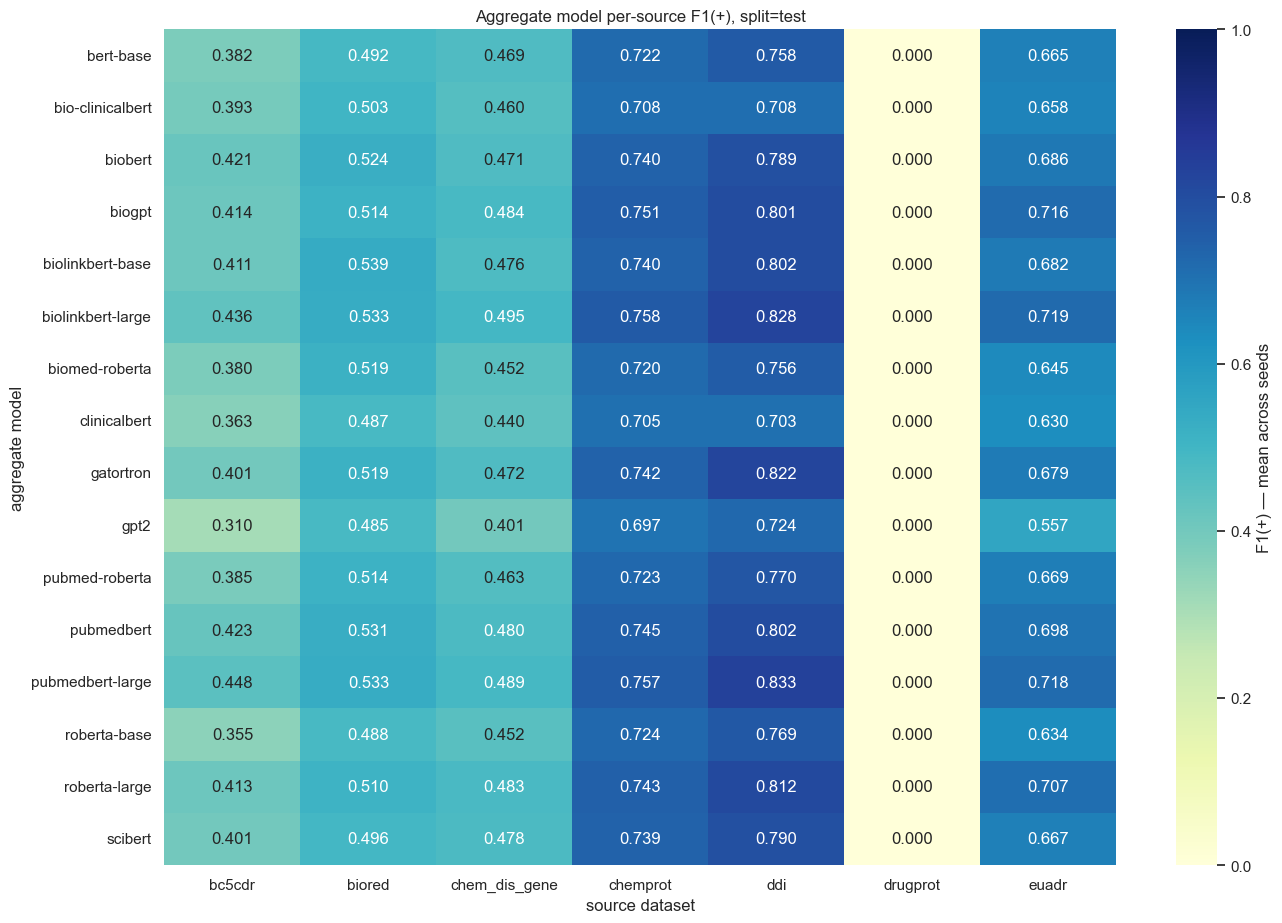

In [13]:
# Heatmap: rows=model, cols=source, cells=aggregate mean F1(+)
if len(df_bin):
    pivot = df_bin.groupby(["model", "source"])["f1_positive"].mean().unstack("source")
    fig, ax = plt.subplots(figsize=(1.4 * pivot.shape[1] + 4, 0.4 * pivot.shape[0] + 3))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1,
                cbar_kws={"label": "F1(+) — mean across seeds"}, ax=ax)
    ax.set_title(f"Aggregate model per-source F1(+), split={SPLIT}")
    ax.set_xlabel("source dataset")
    ax.set_ylabel("aggregate model")
    plt.tight_layout()
    plt.show()

/var/folders/77/6_y2xlqd7p9_8krl2_8py60rwwsbrb/T/ipykernel_3949/4253161962.py:28: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
/Users/basel.alshaikhdeeb/medre-bench/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


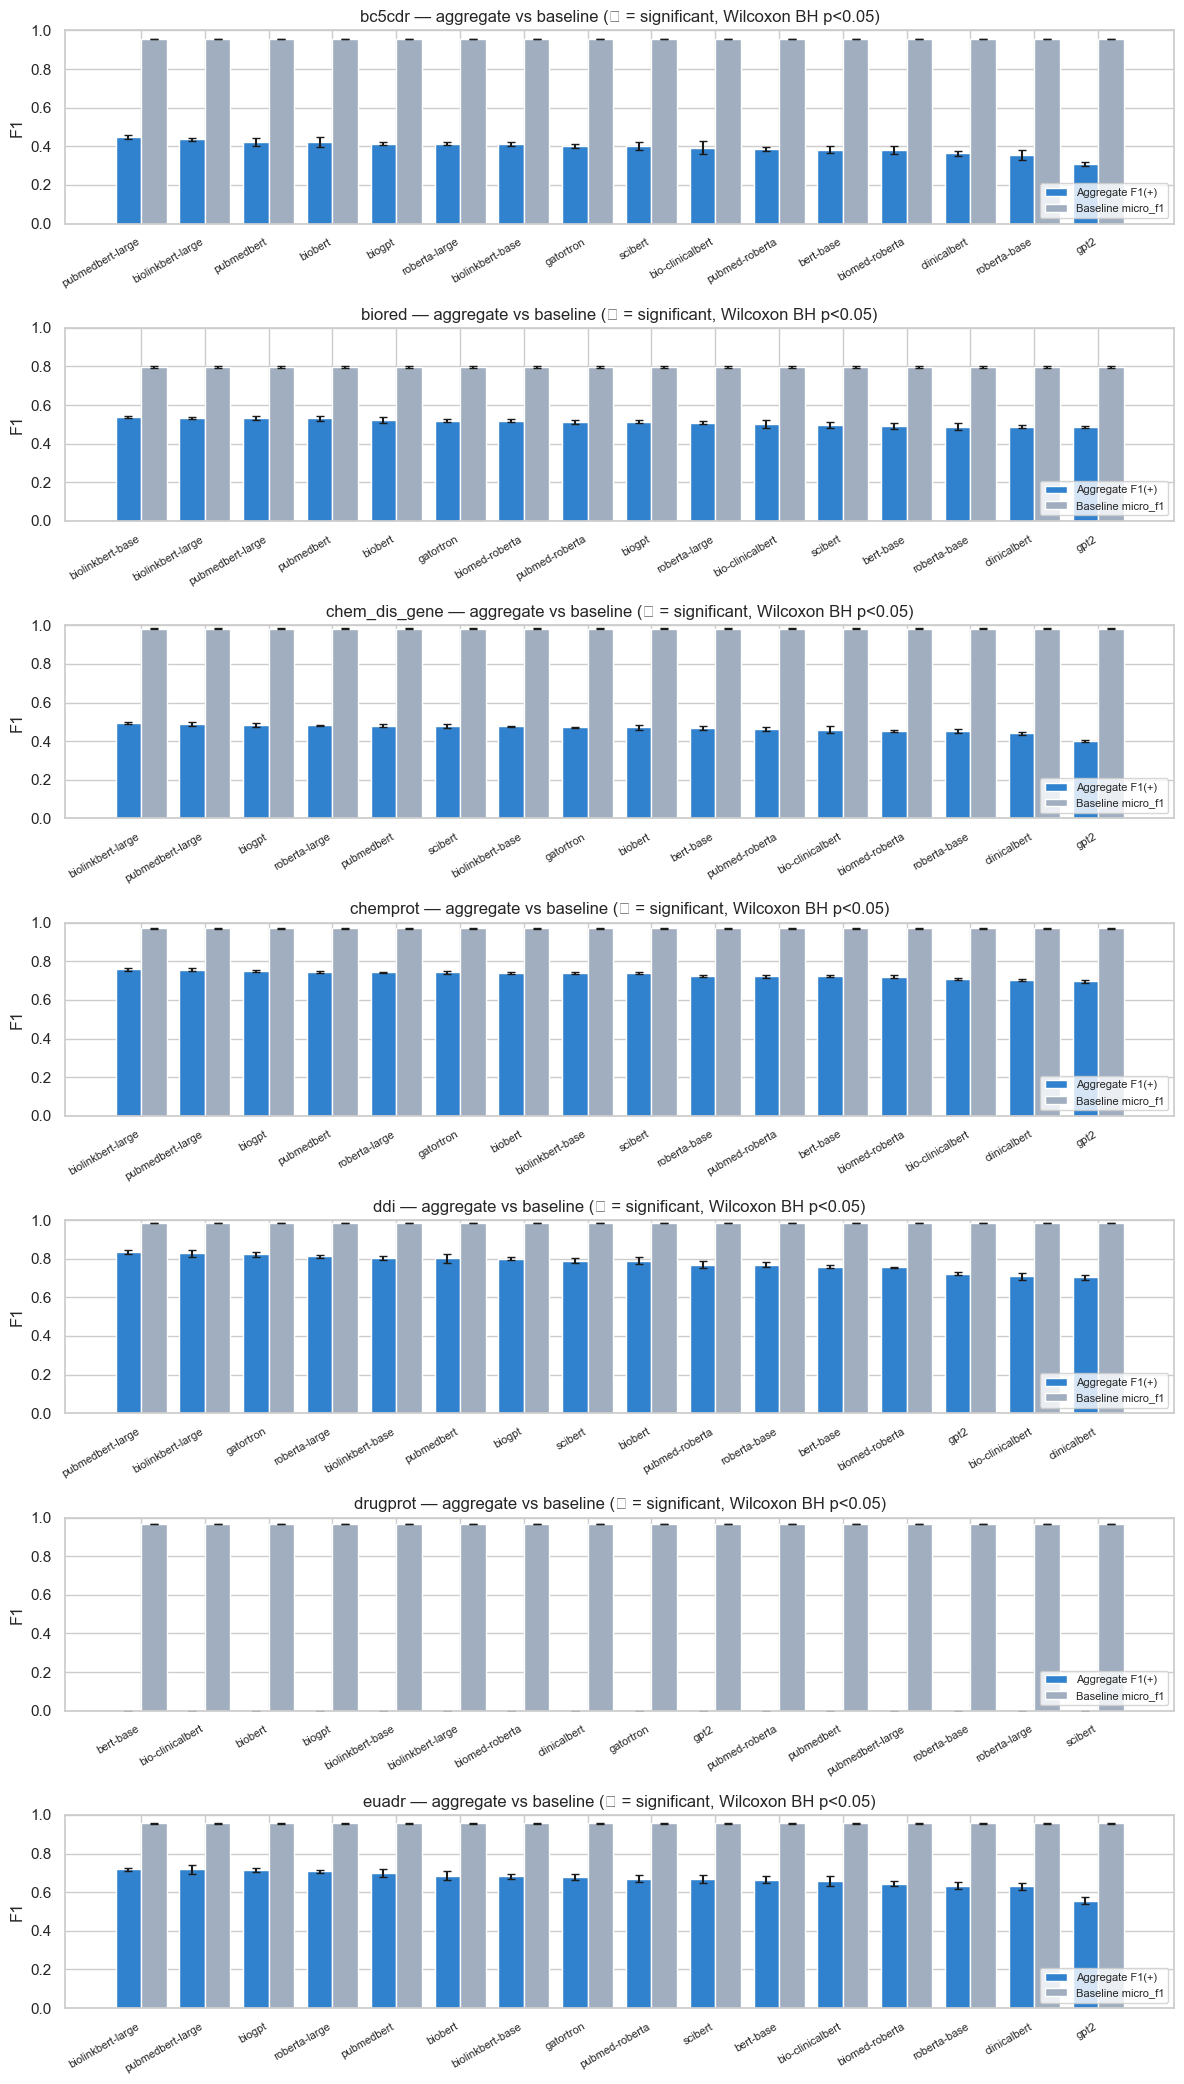

In [14]:
# Paired bars: for each source, side-by-side aggregate F1(+) vs baseline micro_f1, per aggregate model
if len(df_sig):
    sources = sorted(df_sig["source"].unique())
    fig, axes = plt.subplots(len(sources), 1, figsize=(12, 3 * len(sources)), sharex=False)
    if len(sources) == 1:
        axes = [axes]
    for ax, src in zip(axes, sources):
        sub = df_sig[df_sig["source"] == src].sort_values("_agg_mean", ascending=False)
        x = np.arange(len(sub))
        ax.bar(x - 0.2, sub["_agg_mean"].values, width=0.4,
               yerr=sub["_agg_std"].fillna(0).values,
               label="Aggregate F1(+)", color="#3182ce", capsize=3)
        ax.bar(x + 0.2, sub["_bl_mean"].values, width=0.4,
               yerr=sub["_bl_std"].fillna(0).values,
               label="Baseline micro_f1", color="#a0aec0", capsize=3)
        # star significant rows
        for i, sig in enumerate(sub["significant_bh"]):
            if sig:
                y = max(sub["_agg_mean"].iloc[i] + sub["_agg_std"].fillna(0).iloc[i],
                        sub["_bl_mean"].iloc[i] + sub["_bl_std"].fillna(0).iloc[i]) + 0.03
                ax.text(i, min(y, 0.97), "*", ha="center", fontsize=14, color="crimson")
        ax.set_xticks(x)
        ax.set_xticklabels(sub["model"], rotation=30, ha="right", fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f"{src} — aggregate vs baseline (★ = significant, Wilcoxon BH p<0.05)")
        ax.set_ylabel("F1")
        ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

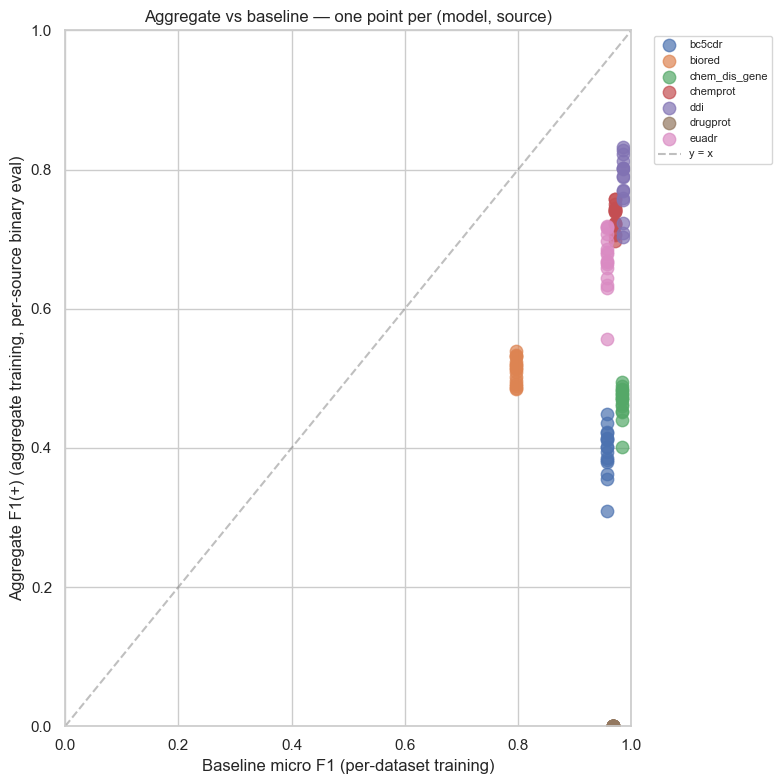

In [15]:
# Scatter: aggregate F1(+) vs baseline micro_f1, one point per (model, source)
if len(df_sig):
    scat = df_sig.dropna(subset=["_agg_mean", "_bl_mean"]).copy()
    fig, ax = plt.subplots(figsize=(8, 8))
    for src in sorted(scat["source"].unique()):
        s = scat[scat["source"] == src]
        ax.scatter(s["_bl_mean"], s["_agg_mean"], s=80, alpha=0.7, label=src)
    ax.plot([0, 1], [0, 1], "--", color="gray", alpha=0.5, label="y = x")
    # annotate significant points
    for _, r in scat[scat["significant_bh"]].iterrows():
        ax.annotate(f"★ {r['model'][:12]}",
                    (r["_bl_mean"], r["_agg_mean"]),
                    xytext=(4, 4), textcoords="offset points",
                    fontsize=7, color="crimson")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Baseline micro F1 (per-dataset training)")
    ax.set_ylabel("Aggregate F1(+) (aggregate training, per-source binary eval)")
    ax.set_title("Aggregate vs baseline — one point per (model, source)")
    ax.legend(bbox_to_anchor=(1.03, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. How to read the tables and plots

**Table 3's `delta` column** is `agg_mean − baseline_mean`. Positive = aggregate wins on average; negative = baseline wins. Doesn't mean much on its own without the p-value or effect size.

**`cohens_d`** is the practical-significance measure. Rules of thumb for paired designs: |d| ≈ 0.2 small, 0.5 medium, 0.8 large. Given only 5 seeds you can have a *large* effect that isn't statistically significant (n too small), or a *statistically significant but tiny* difference (unlikely at this sample size). Report both together.

**`wilcoxon_p_bh`** is what you'd cite in a paper: the FDR-corrected one-sided Wilcoxon p-value over all comparisons in this notebook. The `star` in the bar chart flags `wilcoxon_p_bh < 0.05`.

**Sample size limitation.** With 5 seeds, the smallest achievable one-sided Wilcoxon p is `2/32 ≈ 0.031` (all 5 pairs show aggregate > baseline). So even a perfect win still barely crosses p<0.05 before correction, and gets pushed above 0.05 by BH once you correct across many sources. If you want higher power, either add more seeds or run a parametric paired t-test (which the notebook already computes as `ttest_p`).

**Mode caveat.** When `bl_mode = multi`, the baseline's `micro_f1` is over the full label set (5-13 classes depending on the dataset), while aggregate's `f1(+)` is binary. Numerically they measure different things. Section 4's second table filters to `bl_mode = binary` — read that one for strict comparisons. The `mode` column in Section 3 lets you see at a glance which rows are apples-to-apples.